## Training
Prepapre dataset with the prepare_dataset notebook, before running this one.

In [1]:
from torch.utils.data import DataLoader
# from tqdm import tqdm
from time import time, sleep
import numpy as np
import os
import warnings; warnings.filterwarnings("ignore")
from utils import *
  
# DEV = torch.device(CPU) # for debugging, use cpu
os.makedirs(f"{SAVE_DIR}", exist_ok=True)
print(f'DEV: {DEV}, has_screen: {LOCAL}, job id: {JOBID}')

# copy the python training to the directory (for cluster) (for local, it fails silently)
os.system(f"cp train.py {SAVE_DIR}/train.py")
os.system(f"cp utils.py {SAVE_DIR}/utils.py")

Running JOBID: local, on cpu. NCORES: 16
Using PHYSICS_LS = 32, PTSH = 32, PHYSH = 48, HEADH = 48
BIAS = True
DEV: cpu, has_screen: True, job id: local


cp: cannot stat 'train.py': No such file or directory


0

In [2]:
EPOCHS = 12 if LOCAL else 50 # number of epochs 100 <-
# BATCH_SIZE = 128 # 128 
BATCH_SIZE = 64 if LOCAL else 256 # 64 <-
PTS_PER_SAMPLE = 10 if LOCAL else 100 # number of points to pick for each training sample in the ds, must be a perfect divider of total number of pts per time instant
print(f'EPOCHS: {EPOCHS}, BATCH_SIZE: {BATCH_SIZE}, PTS_PER_SAMPLE: {PTS_PER_SAMPLE}')

LOAD_PRETRAINED = None # Set it to None if you don't want to load pretrained model
# LOAD_PRETRAINED = 'data/3452622/best_Fx.pth' # best with MSE loss (small)
# LOAD_PRETRAINED = 'data/3452764/best_Fx.pth' # best with L1 loss (small) 
# LOAD_PRETRAINED = 'data/3456052/best_Fx.pth' # finetuned over 3452764 (small), 
# LOAD_PRETRAINED = 'data/3456791/best_Fx.pth' # best l1 loss turbosmall 
# LOAD_PRETRAINED = 'data/3535303/best_Fx.pth' # best with L1 loss (small) (3.5 mil ds)

EPOCHS: 12, BATCH_SIZE: 64, PTS_PER_SAMPLE: 10


In [3]:
# schedulers
from numpy import concatenate as cat, linspace as linsp, logspace as logsp
### learning rate
LR = 5e-3*logsp(0, -2, EPOCHS) # <- [good]
# LR = 3e-4*logsp(0, -2, EPOCHS) 
# LR = 3e-3*np.ones(EPOCHS) 
# LR = 3e-3*logsp(0, -2, EPOCHS)  
# LR = 1e-3*np.ones(EPOCHS) if LOCAL else 1e-3*logsp(0, -2, EPOCHS) # <-
if LOAD_PRETRAINED is not None: LR = 5e-4*linsp(1, 0.1, EPOCHS); print('reducing LR for pretrained model') # reduce lr if loading pretrained model

### loss ratios 

# standard training
R_FX=np.ones(EPOCHS); R_IY=1e-2*logsp(0,-4,EPOCHS); R_B=np.zeros(EPOCHS); R_BD=0.5*np.ones(EPOCHS); R_IYD=np.zeros(EPOCHS)

# # Iy training
# R_FX=logsp(0,-4,EPOCHS); R_IY=0.1*np.ones(EPOCHS); R_B=np.zeros(EPOCHS); R_BD=0.1*logsp(0,-4,EPOCHS); R_IYD=np.zeros(EPOCHS)


# ## TEST CONF
# ## Fx
# R_FX = np.ones(EPOCHS) # <-
# # R_FX = 1.0 * logsp(0, -4, EPOCHS) # <- for Iy estimate
# # R_FX = np.zeros(EPOCHS) 
# # R_FX = 1e-5*np.ones(EPOCHS) 

# ## Iy
# # R_IY  = 0.1 * logsp(0, -4, EPOCHS) 
# # R_IY  = 0.1 * np.ones(EPOCHS) 
# R_IY = np.zeros(EPOCHS) # <- best for Fx

# ## Br Bz
# # R_B = 0.1 * np.ones(EPOCHS) 
# # R_B = 1.0 * np.ones(EPOCHS) 
# # R_B = 0.1 * logsp(0, -4, EPOCHS) 
# R_B = np.zeros(EPOCHS) # <- [best, use grad of Fx to get Br Bz]

# ## Br Bz from derivative, PINN
# R_BD = 1e-1 * np.ones(EPOCHS) # <-
# # R_BD = np.ones(EPOCHS) 
# # R_BD = 1e-5*np.ones(EPOCHS) 
# # R_BD = np.zeros(EPOCHS)  

# ## Iy from second derivative, PINN
# R_IYD = 1e-2 * np.ones(EPOCHS) # <-
# # R_IYD = np.zeros(EPOCHS)

ACTIVE_LOSSES = [np.sum(l_profile) > 0 for l_profile in [R_FX, R_IY, R_B, R_BD, R_IYD]]


In [4]:
#checks
if LOAD_PRETRAINED is not None: assert os.path.exists(LOAD_PRETRAINED), "Pretrained model does not exist"
assert os.path.exists(TRAIN_DS_PATH), "Training dataset does not exist"
assert os.path.exists(EVAL_DS_PATH), "Evaluation dataset does not exist"
assert os.path.exists(SAVE_DIR), "Save directory does not exist"
assert len(LR) == EPOCHS, "Learning rate array length does not match epochs"
assert len(R_FX) == EPOCHS, "R_FX loss ratio array length does not match epochs"
assert len(R_IY) == EPOCHS, "R_IY loss ratio array length does not match epochs"
assert len(R_B) == EPOCHS, "R_B loss ratio array length does not match epochs"
assert len(ACTIVE_LOSSES) == len(LOSS_NAMES), "ACTIVE_LOSSES length does not match LOSS_NAMES"

In [5]:
# # test net I/O
test_network_io()

test_network_io
single liuqeML -> in: [torch.Size([1, 134]), torch.Size([1, 5, 2])], 
            out: [torch.Size([1, 5]), torch.Size([1, 5, 2]), torch.Size([1, 5])]
batched liuqeML -> in: [torch.Size([7, 134]), torch.Size([7, 5, 2])], 
            out: [torch.Size([7, 5]), torch.Size([7, 5, 2]), torch.Size([7, 5])]


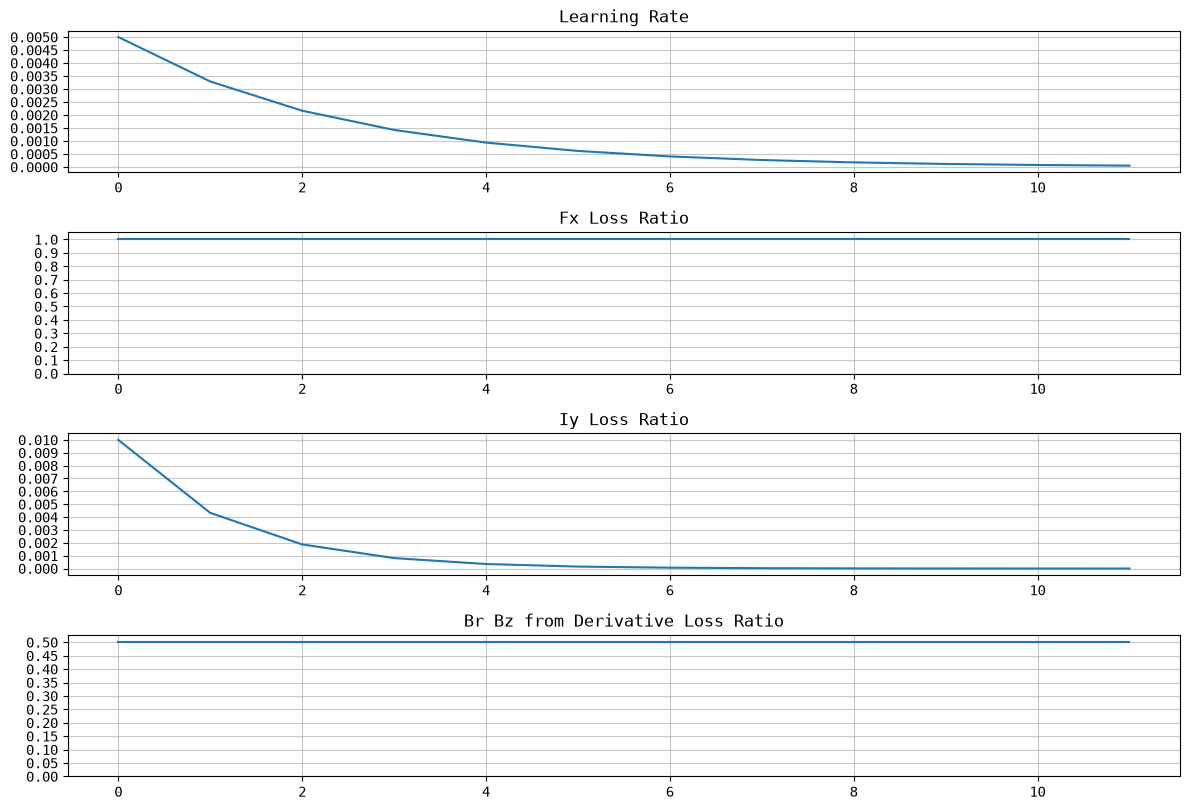

In [6]:
# plot schedulers
n_ticks = 11
plt.figure(figsize=(12, 12))
titles = ['Learning Rate', 'Fx Loss Ratio', 'Iy Loss Ratio', 'Br Bz Loss Ratio', 'Br Bz from Derivative Loss Ratio', 'Iy from 2nd Derivative Loss Ratio']
pi = 2 # plot index
plt.subplot(len(ACTIVE_LOSSES)+1, 1, 1), plt.plot(LR), plt.yticks(np.linspace(0, np.max(LR), n_ticks)), plt.title(titles[0])
active_idxs = [i for i, active in enumerate(ACTIVE_LOSSES) if active]
for i, r in enumerate([LR, R_FX, R_IY, R_B, R_BD, R_IYD]):
    if i==0 or not ACTIVE_LOSSES[i-1]: continue
    plt.subplot(len(ACTIVE_LOSSES)+1, 1, pi), plt.plot(r), plt.yticks(np.linspace(0, np.max(r), n_ticks)), plt.title(titles[i])
    pi += 1
plt.tight_layout()
plt.show() if LOCAL else plt.savefig(f"{SAVE_DIR}/schedulers.png")

Dataset loaded from dss/train_ds.npz, keys: dict_keys(['phys', 'pts', 'Fx', 'Iy', 'Br', 'Bz'])
Dataset: n_t:1600, total_pts_per_t:500, picked:10 -> N:80000 (1600*500//10), memory:20.0576MB, on_dev:False
Dataset loaded from dss/eval_ds.npz, keys: dict_keys(['phys', 'pts', 'Fx', 'Iy', 'Br', 'Bz'])
Dataset: n_t:400, total_pts_per_t:500, picked:10 -> N:20000 (400*500//10), memory:5.0144MB, on_dev:False
test_dataset
Dataset length: 20000
Inputs: X -> torch.Size([134]), r -> torch.Size([10, 2]), z -> torch.Size([10])
Outputs: Y1 -> torch.Size([10]), Y2 -> torch.Size([10]), Y3 -> torch.Size([10])
20000


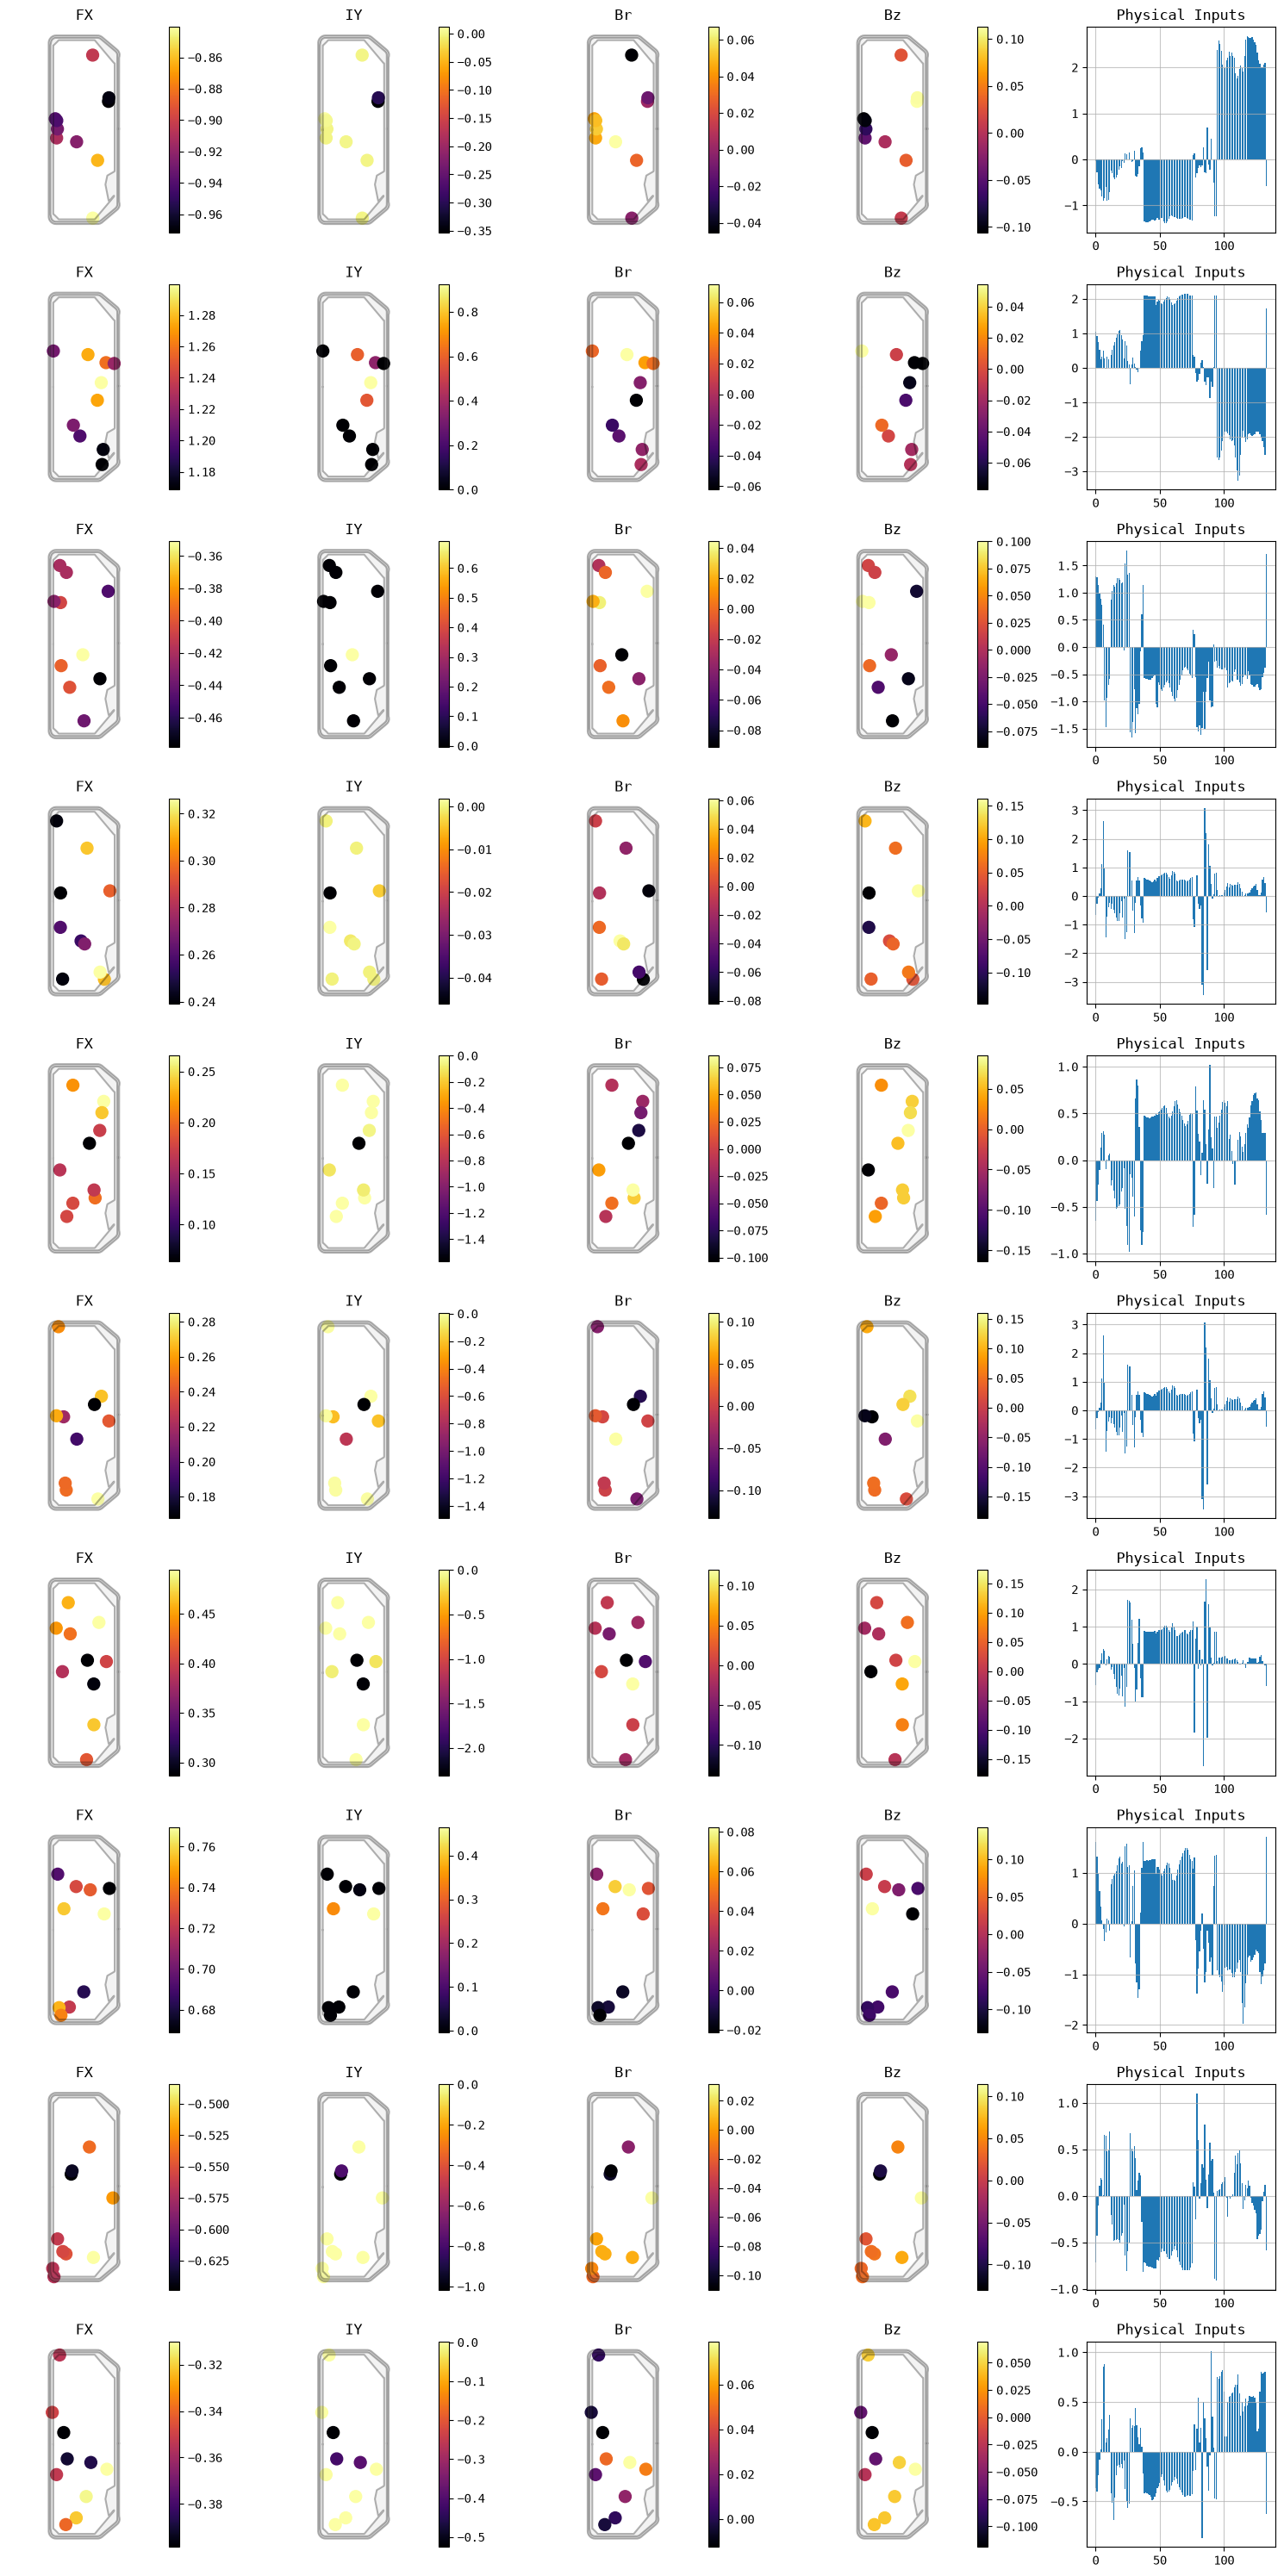

In [7]:
# create training and evaluation datasets
train_ds = LiuqeDataset(TRAIN_DS_PATH, pts_per_sample=PTS_PER_SAMPLE)
val_ds = LiuqeDataset(EVAL_DS_PATH, pts_per_sample=PTS_PER_SAMPLE)
test_dataset(val_ds)
#save the mean_std of the dataset int the save directory
np.savez(f"{SAVE_DIR}/x_mean_std.npz", x_mean_std=train_ds.x_mean_std.cpu().numpy())

## Training

In [8]:
train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True) # initialize DataLoader
val_dl = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False) # initialize DataLoader
# network
model = liuqeML(train_ds.x_mean_std)
opt = torch.optim.Adam(model.parameters(), lr=LR[0])# adam
# opt = torch.optim.AdamW(model.parameters(), lr=LR[0], weight_decay=1e-4) # adamw
# opt = torch.optim.Muon(model.parameters(), lr=LR[0]) # Muon optimizer

if LOAD_PRETRAINED is not None: # load pretrained model
    model.load_state_dict(torch.load(LOAD_PRETRAINED, map_location=torch.device(CPU)), strict=STRICT_LOAD) # load pretrained model
    print(f"Pretrained model loaded: {LOAD_PRETRAINED}")

model.to(DEV) # move model to DEV
# loss_fn = F.mse_loss # Mean Squared Error
loss_fn = F.l1_loss # Mean Absolute Error
print(f"Using loss function: {loss_fn.__name__}")
tlog, elog = np.inf*np.ones((EPOCHS, len(train_dl), len(LOSS_NAMES))), np.inf*np.ones((EPOCHS, len(val_dl), len(LOSS_NAMES))) # init log
start_time = time() # start time
print("Ep:   || fx    | iy  |  b  |  bd | iyd || r:fx| r:iy| r:b | r:bd|r:iyd| LR  || t  | eta| improved    ")
for ep in range(EPOCHS): # epochs
    epoch_time = time()
    for pg in opt.param_groups: pg['lr'] = LR[ep] # update learning rate
    model.train()
    for ib, batch in enumerate(train_dl):
        if train_ds.on_dev: x, p, fx, iy, br, bz = batch # unpack batch
        else: x, p, fx, iy, br, bz = map(lambda t: t.to(DEV), batch) # move to DEV
        r = p.clone()[:,:,0] # r coordinates
        p.requires_grad = True # enable gradients for p

        ##  TESTS
        # put noise to some parts of the inputs 
        in_masked = get_in_masks([IA,UF,RBT]) # mask Ia, Uf, Rbt
        # in_masked = get_in_masks([]) # unchanged
        # in_masked = get_in_masks([BM, FF, UF, RBT]) # keep only Ia (kinda works)
        # in_masked = get_in_masks([UF, RBT]) # mask Uf, Rbt
        μx, σx = train_ds.x_mean_std[0, in_masked].to(DEV), train_ds.x_mean_std[1, in_masked].to(DEV)
        x[:, in_masked] = μx + σx * torch.randn_like(x[:, in_masked], ) * ep*0.1

        
        opt.zero_grad() # zero gradients
        fxp, brzp, iyp = model(x, p) # forward pass
        brp, bzp = brzp[:,:,0], brzp[:,:,1] # unpack into br and bz

        if R_BD[ep] > 0 or R_IYD[ep] > 0: # calculate only if needed
            # calculate first derivatives of Fx wrt r and z, for Br Bz
            dfx_drz, = torch.autograd.grad(outputs=fxp.sum(), inputs=p, create_graph=True)
            dfx_dr, dfx_dz = dfx_drz[:,:,0], dfx_drz[:,:,1] # derivative of Fx wrt r and z
            brpd = -dfx_dz / (2*π*r) # Br from derivative
            bzpd = dfx_dr / (2*π*r) # Bz from derivative
            if R_IYD[ep] > 0:
                # calculate second derivatives of Fx wrt r and z for Iy
                d2fx_dr2 = torch.autograd.grad(outputs=dfx_dr.sum(), inputs=p, create_graph=True)[0][:,:,0]
                d2fx_dz2 = torch.autograd.grad(outputs=dfx_dz.sum(), inputs=p, create_graph=True)[0][:,:,1]
                iydp = - (1/(2*π*r) * d2fx_dz2 + 1/(2*π*r) * d2fx_dr2 - 1/(2*π*r**2) * dfx_dr)
            else: iydp = iy # dummy
        else: brpd, bzpd, iydp = br, bz, iy # dummy

        # losses
        l_fx = loss_fn(fx, fxp) # fx loss
        l_iy = loss_fn(iy, iyp) # iy loss
        l_brz = loss_fn(br, brp) + loss_fn(bz, bzp) # br bz loss
        l_brzd = loss_fn(br, brpd) + loss_fn(bz, bzpd) # br bz loss from derivative
        l_iyd = loss_fn(iy, iydp) # iy loss from second derivative

        loss = R_FX[ep]*l_fx + R_IY[ep]*l_iy + R_B[ep]*l_brz + R_BD[ep]*l_brzd + R_IYD[ep]*l_iyd # total loss
        loss.backward() # backprop

        # torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0) # gradient clipping

        opt.step() # update weights

        tlog[ep, ib] = [l.item() for l in (l_fx, l_iy, l_brz, l_brzd, l_iyd)] # save batch losses

    model.eval() # evaluation mode
    with torch.no_grad(): # Disable gradients for most of the validation
        for ib, batch in enumerate(val_dl):
            if val_ds.on_dev: x, p, fx, iy, br, bz = batch # unpack batch
            else: x, p, fx, iy, br, bz = map(lambda t: t.to(DEV), batch) # move to DEV
            with torch.enable_grad():
                p.requires_grad = True # enable gradients for p
                fxp, brzp, iyp = model(x, p) # forward pass
                brp, bzp = brzp[:,:,0], brzp[:,:,1] # unpack outputs
                r = p.clone()[:,:,0] # r coordinates    
                if R_BD[ep] > 0: dfx_drz, = torch.autograd.grad(outputs=fxp.sum(), inputs=p, create_graph=True)
                else: dfx_drz = torch.zeros_like(p)
                dfx_dr, dfx_dz = dfx_drz[:,:,0], dfx_drz[:,:,1] # derivative of Fx wrt r and z
                if R_BD[ep] > 0: 
                    # calculate second derivatives of Fx wrt r and z for Iy
                    d2fx_dr2 = torch.autograd.grad(outputs=dfx_dr.sum(), inputs=p, create_graph=True)[0][:,:,0]
                    d2fx_dz2 = torch.autograd.grad(outputs=dfx_dz.sum(), inputs=p, create_graph=True)[0][:,:,1]
                else: d2fx_dr2 = torch.zeros_like(r); d2fx_dz2 = torch.zeros_like(r)
            brpd = -dfx_dz / (2*π*r) # Br from derivative
            bzpd = dfx_dr / (2*π*r) # Bz from derivative
            iydp = - (1/(2*π*r) * d2fx_dz2 + 1/(2*π*r) * d2fx_dr2 - 1/(2*π*r**2) * dfx_dr) # Iy from second derivative
            # losses
            l_fx = loss_fn(fx, fxp) # fx loss
            l_iy = loss_fn(iy, iyp) # iy loss
            l_brz = loss_fn(br, brp) + loss_fn(bz, bzp) # br bz loss
            l_brzd = loss_fn(br, brpd) + loss_fn(bz, bzpd) # br bz loss from derivative
            l_iyd = loss_fn(iy, iydp) # iy loss from second derivative
            elog[ep, ib] = [l.item() for l in (l_fx, l_iy, l_brz, l_brzd, l_iyd)] # save batch losses

    # save model if improved
    endp = ""
    if LOAD_PRETRAINED is not None and ep==1: elog[0,:,:] = 1.1*elog[1,:,:] # penalize first epoch eval losses if pretrained model is loaded
    epoch_losses = np.mean(elog[ep,:,:], axis=0) # epoch losses: mean across batchess
    best_losses = np.min(np.mean(elog[:ep,:,:], axis=1), axis=0) if ep > 0 else epoch_losses # best losses: min across epochs
    for el, bl, n in zip(epoch_losses, best_losses, LOSS_NAMES):
        if el <= bl: torch.save(model.state_dict(), model_path(n)); endp+=f"*{n}"
    # print progress
    print(f"{ep+1:03d}/{EPOCHS:02d}||" + f"{epoch_losses[0]:.1e}|" +
        '|'.join([f"{v:.0e}" for v in epoch_losses[1:]]) + "||" +
        f"{R_FX[ep]:.0e}|{R_IY[ep]:.0e}|{R_B[ep]:.0e}|{R_BD[ep]:.0e}|{R_IYD[ep]:.0e}|{LR[ep]:.0e}||" +
        f"{int(time()-epoch_time):03d}s|{int((time()-start_time)*(EPOCHS-ep)/(ep+1)/(1 if LOCAL else 60)):03d}{'s' if LOCAL else 'm'}|", end=endp+'\n')

tlosses, elosses = np.mean(tlog, axis=1), np.mean(elog, axis=1) # losses across epochs
print(f"Training time: {(time()-start_time)/60:.0f}mins")
print(f"Best {loss_fn.__name__}: " + ", ".join([f"{n} {bl:.3e} (ep {be})" for n, bl, be in zip(LOSS_NAMES, np.min(elosses, axis=0), np.argmin(elosses, axis=0))]))
if loss_fn == F.mse_loss: print("Estimated MAE: " + ", ".join([f"{n} {np.sqrt(np.min(np.mean(elog[:,:,i], axis=1))):.3e}" for i, n in enumerate(LOSS_NAMES)]))
if loss_fn == F.l1_loss: print("Estimated RMSE: " + ", ".join([f"{n} {np.min(np.mean(elog[:,:,i], axis=1))**2:.3e}" for i, n in enumerate(LOSS_NAMES)]))
np.save(f"{SAVE_DIR}/train_losses.npy", tlosses) # save training losses
np.save(f"{SAVE_DIR}/eval_losses.npy", elosses) # save evaluation losses

Using loss function: l1_loss
Ep:   || fx    | iy  |  b  |  bd | iyd || r:fx| r:iy| r:b | r:bd|r:iyd| LR  || t  | eta| improved    
001/12||1.9e-02|1e-01|1e-01|3e-02|2e-01||1e+00|1e-02|0e+00|5e-01|0e+00|5e-03||015s|182s|*Fx*Iy*B*Bd*Iyd
002/12||1.2e-02|9e-02|1e-01|2e-02|1e-01||1e+00|4e-03|0e+00|5e-01|0e+00|3e-03||014s|164s|*Fx*Iy*Bd*Iyd
003/12||9.0e-03|8e-02|1e-01|2e-02|1e-01||1e+00|2e-03|0e+00|5e-01|0e+00|2e-03||014s|147s|*Fx*Iy*Bd*Iyd
004/12||6.2e-03|8e-02|2e-01|2e-02|1e-01||1e+00|8e-04|0e+00|5e-01|0e+00|1e-03||012s|128s|*Fx*Iy*Bd*Iyd
005/12||5.2e-03|8e-02|2e-01|1e-02|1e-01||1e+00|4e-04|0e+00|5e-01|0e+00|9e-04||012s|111s|*Fx*Iy*Bd*Iyd
006/12||4.7e-03|8e-02|2e-01|1e-02|1e-01||1e+00|2e-04|0e+00|5e-01|0e+00|6e-04||012s|095s|*Fx*Iy*Bd*Iyd
007/12||4.4e-03|8e-02|2e-01|1e-02|1e-01||1e+00|7e-05|0e+00|5e-01|0e+00|4e-04||012s|080s|*Fx*Bd*Iyd
008/12||4.0e-03|8e-02|2e-01|1e-02|1e-01||1e+00|3e-05|0e+00|5e-01|0e+00|3e-04||012s|066s|*Fx*Iy*Bd*Iyd
009/12||3.8e-03|8e-02|2e-01|1e-02|1e-01||1e+00|1e-05|0

Plotting losses...


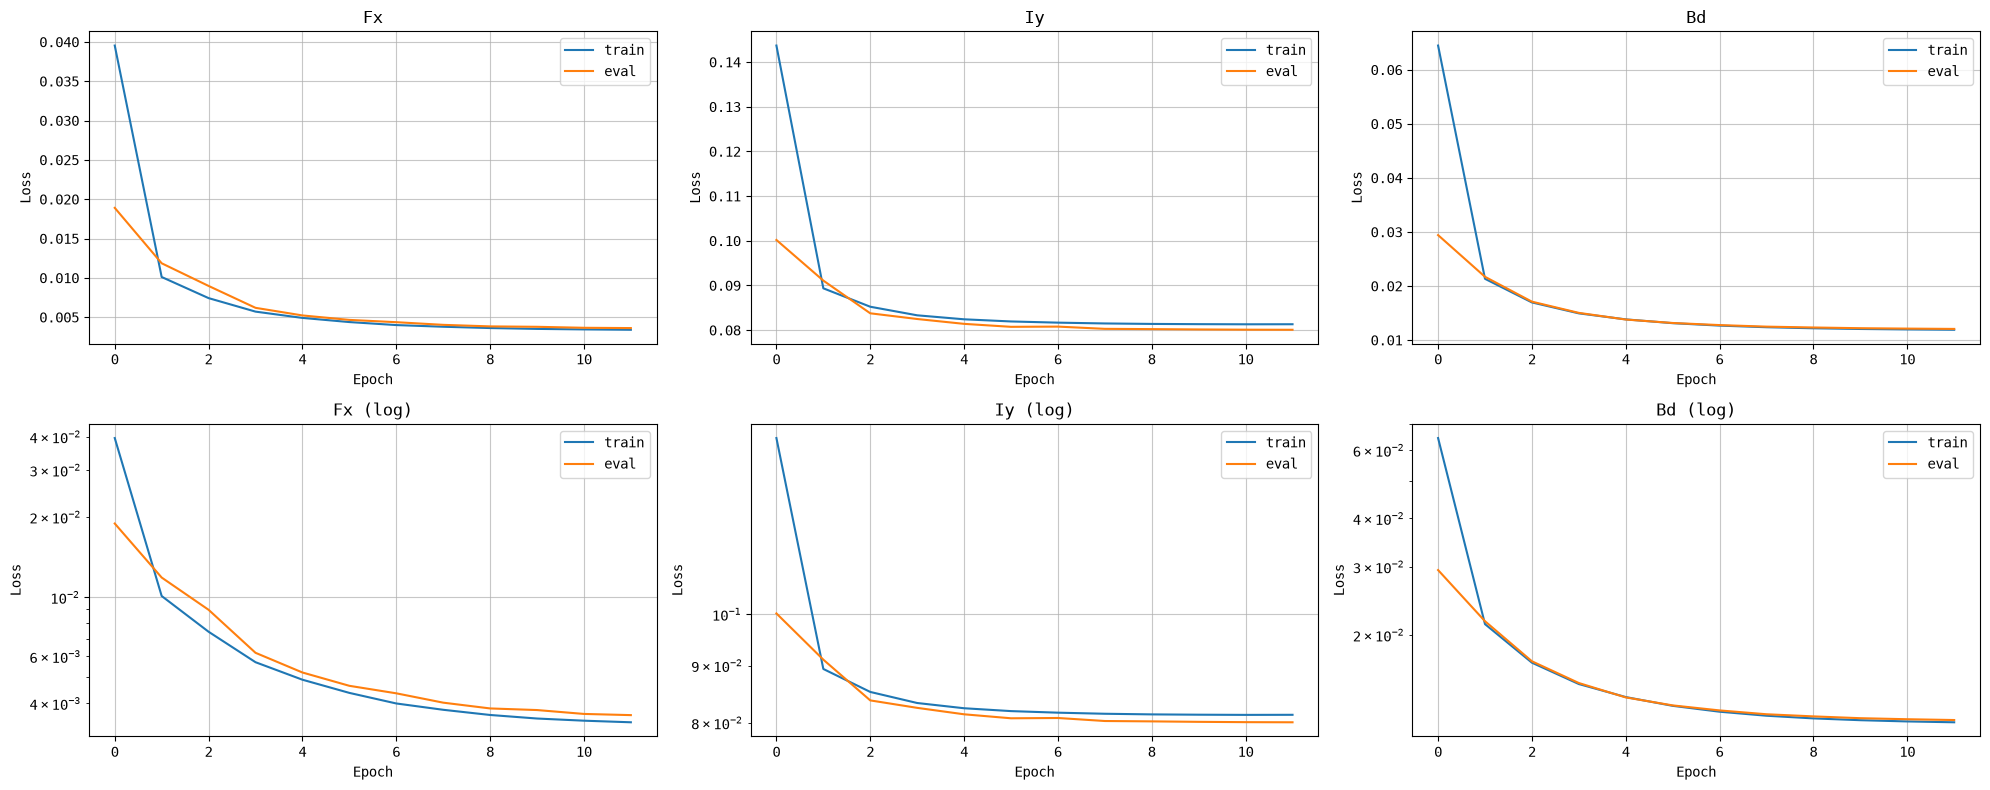

In [9]:
# plot losses
print("Plotting losses...")
# fig, ax = plt.subplots(2, len(LOSS_NAMES), figsize=(4*len(LOSS_NAMES), 8))
fig = plt.figure(figsize=(4*len(LOSS_NAMES), 8))
# Load losses
train_loss = np.load(f"{SAVE_DIR}/train_losses.npy")
eval_loss = np.load(f"{SAVE_DIR}/eval_losses.npy")
n_active_losses = sum(ACTIVE_LOSSES)
active_names = [name for i, name in enumerate(LOSS_NAMES) if ACTIVE_LOSSES[i]]
active_indices = [i for i, active in enumerate(ACTIVE_LOSSES) if active]
for i, name in enumerate(active_names):
    # Linear scale
    plt.subplot(2, n_active_losses, i+1)
    plt.plot(train_loss[:,active_indices[i]], label='train')
    plt.plot(eval_loss[:,active_indices[i]], label='eval')
    plt.title(f"{name}")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    # Log scale
    plt.subplot(2, n_active_losses, i+1 + n_active_losses)
    plt.plot(train_loss[:,active_indices[i]], label='train')
    plt.plot(eval_loss[:,active_indices[i]], label='eval')
    plt.yscale('log')
    plt.title(f"{name} (log)")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
plt.tight_layout()
plt.show() if LOCAL else plt.savefig(f"{SAVE_DIR}/losses.png")

In [10]:
# # KEEP COMMENTED: test pretrained model
# # DATA_DIR_TEST = 'data/3535303' # directory of the dataset to test the pretrained model on 
# DATA_DIR_TEST = 'data/3456052' # directory of the dataset to test the pretrained model on 
# lnn = load_net_from_data(data_dir=DATA_DIR_TEST)
# plot_network_outputs(val_ds, model, nplt=10, use_db=True, use_diy=True) # plot network outputs
# assert False, "We are just testing the pretrained model, stop here."

Testing network output...


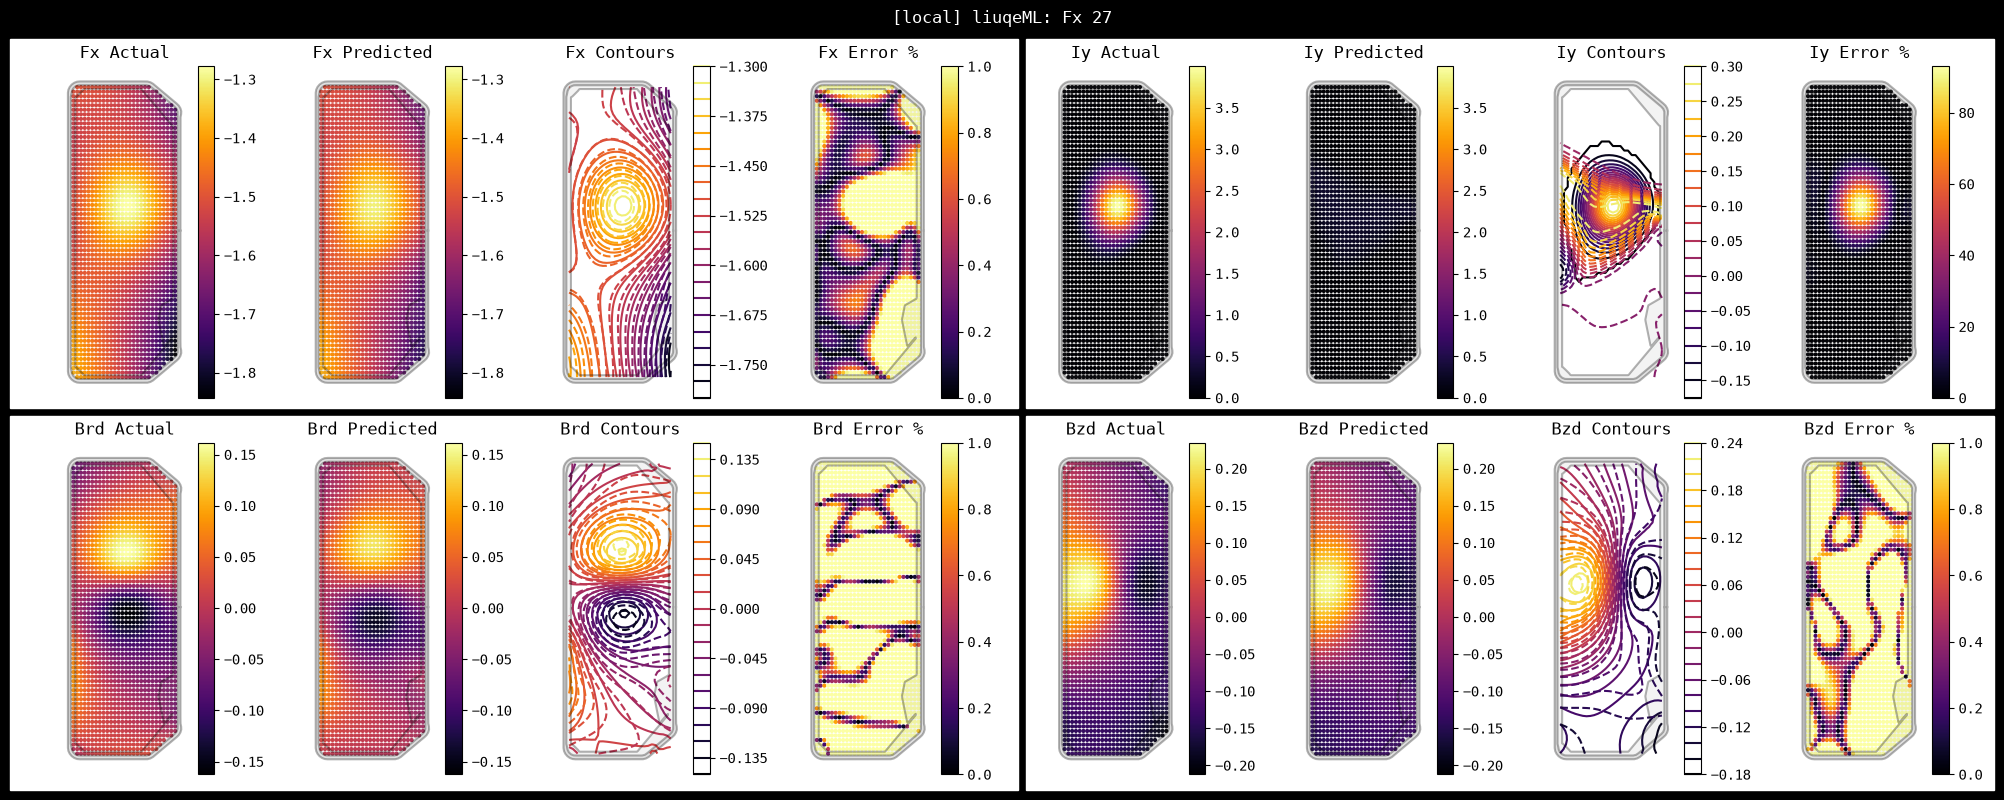

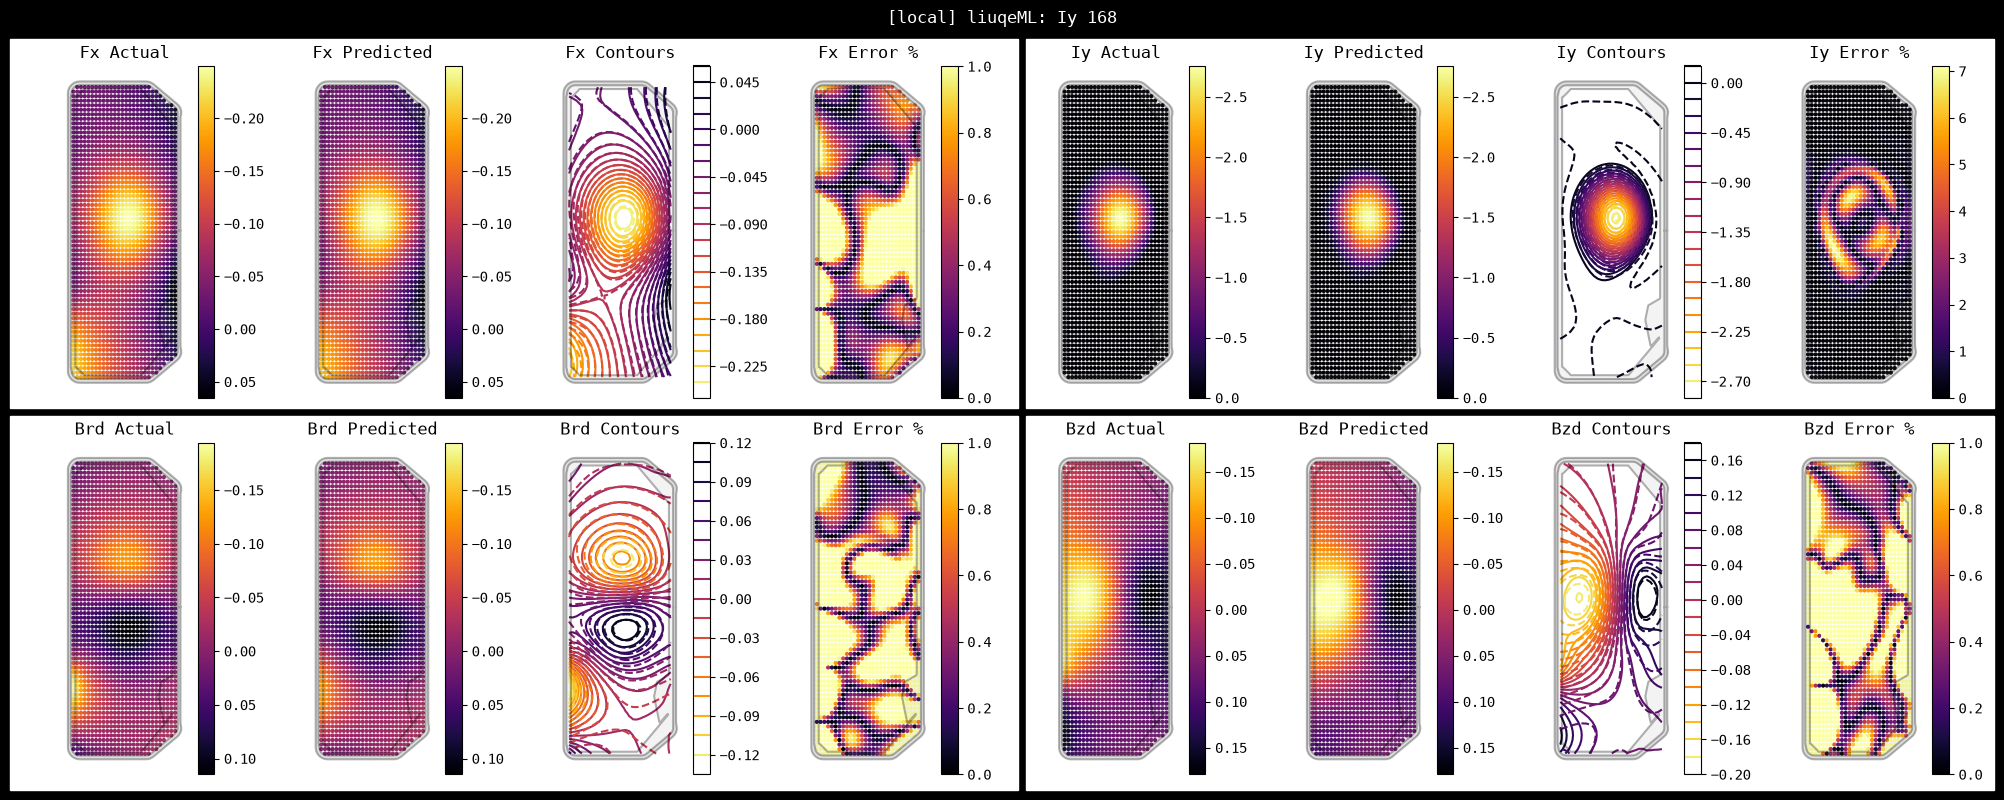

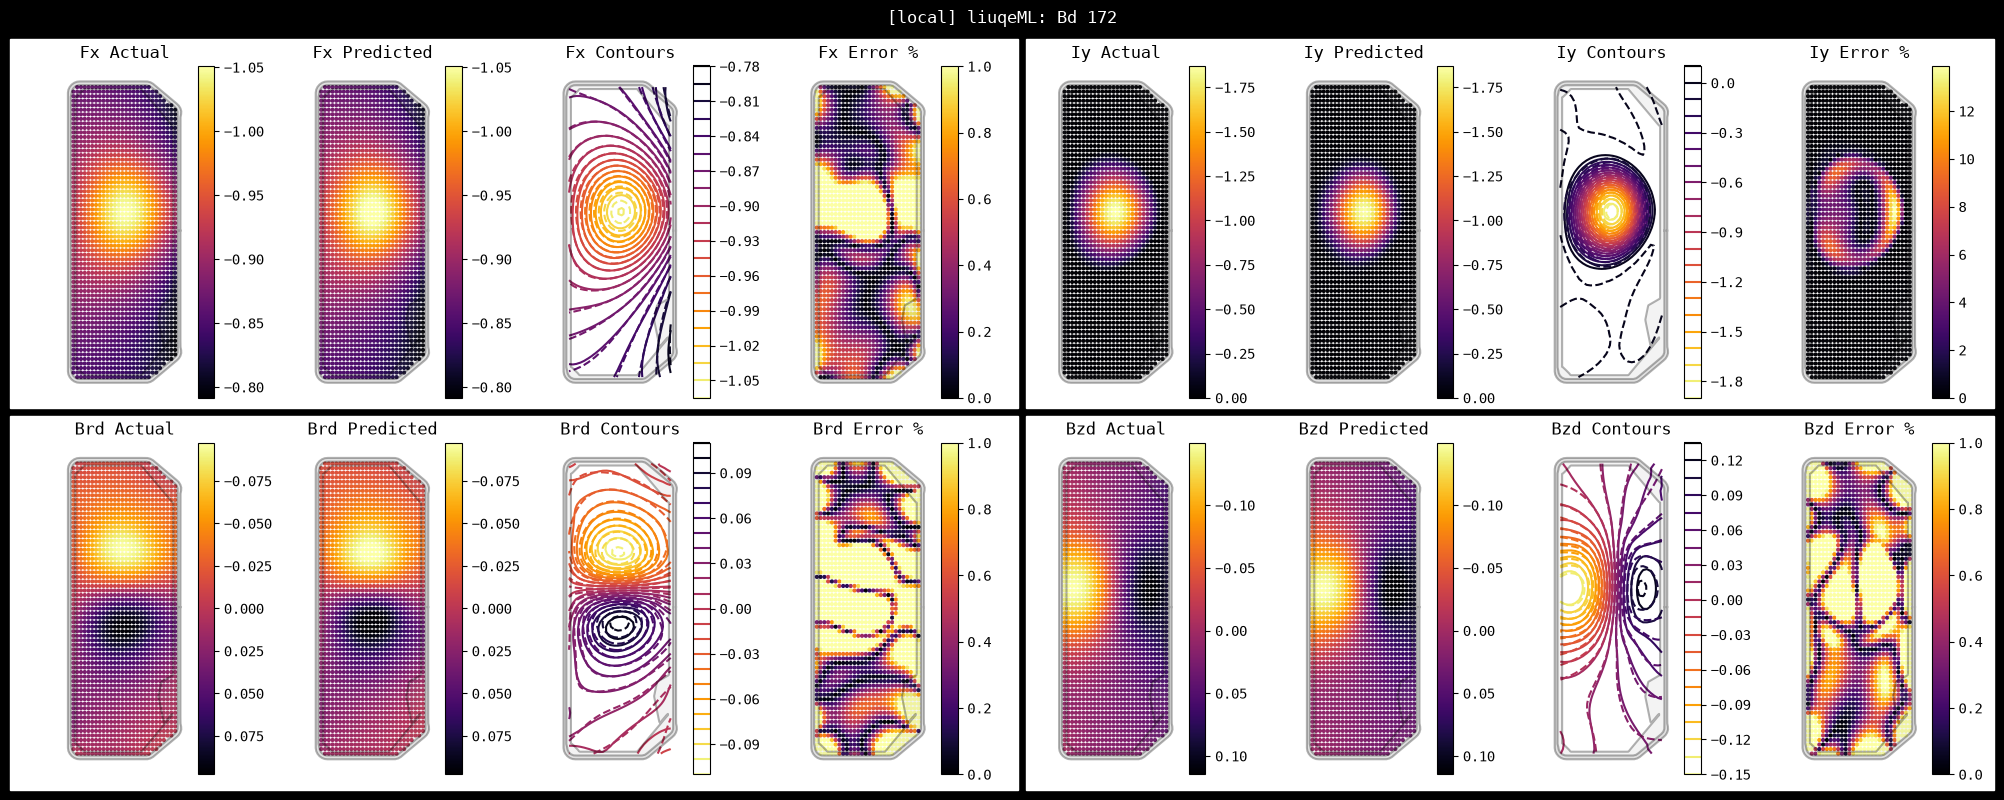

In [11]:
# testing network outputs
print("Testing network output...")
for active, ln in zip(ACTIVE_LOSSES, LOSS_NAMES):
    if not active: continue
    model = liuqeML(train_ds.x_mean_std)
    model.load_state_dict(torch.load(model_path(ln), map_location=torch.device(CPU))) # load pretrained model
    use_db = R_BD[-1] > R_B[-1] or (R_BD[-1] == 0 and R_B[-1] == 0)
    use_diy = R_IYD[-1] > R_IY[-1] or (R_IYD[-1] == 0 and R_IY[-1] == 0)
    plot_network_outputs(val_ds, model, title=ln, use_db=use_db, use_diy=use_diy) # plot network outputs

In [12]:
# save weights to .mat file and .json
m = liuqeML(train_ds.x_mean_std)
for active, ln in zip(ACTIVE_LOSSES, LOSS_NAMES):
    if active:
        m.load_state_dict(torch.load(model_path(ln), map_location=torch.device(CPU))) # load pretrained model
        save_weights_to_mat(m, title=ln)
        save_weights_to_json(m, title=ln)

Weights saved to data/local/weights_Fx.mat
Weights saved to data/local/weights_Fx.json
Weights saved to data/local/weights_Iy.mat
Weights saved to data/local/weights_Iy.json
Weights saved to data/local/weights_Bd.mat
Weights saved to data/local/weights_Bd.json


In [13]:
print(f"{JOBID} done")
if not LOCAL: sleep(30) # wait for files to update (for cluster)
#copy the log file to the folder
os.system(f"cp jobs/{JOBID}.txt {SAVE_DIR}/log.txt")

local done


cp: cannot stat 'jobs/local.txt': No such file or directory


256